## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


---

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# import numpy as np

import os

import kagglehub

import warnings
warnings.filterwarnings("ignore")

In [5]:
### Visualization settings ##

##### Matplotlib ##
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'


#### Pandas ###
#### show the max of columns in a pandas object
pd.set_option('display.max_columns', None)

############ Seaborn ##
# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")

In [6]:
##### Get the data from Kaggle ###
# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
# print("Path to dataset files:", path)

# List all files in the downloaded directory
files = os.listdir(path)
# print("Files in dataset:", files)

# Load the CSV file: Get first CSV file
csv_file = [f for f in files if f.endswith('.csv')][0]  
full_path = os.path.join(path, csv_file)
# print(f"Loading file: {full_path}")

In [7]:
# ============================================
# 1. LOAD AND PREPARE DATA
# ============================================
aws_products = pd.read_csv(full_path)

print(f"Total products: {len(aws_products):}")
print(f"Columns: {aws_products.columns.tolist()}")
print(f"\nFirst few rows:")
display(aws_products.head())

Total products: 2443651
Columns: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

First few rows:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
## Check for missing values ### >> important
aws_products.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [9]:
aws_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [10]:
num = aws_products.select_dtypes(include="number") 
cat = aws_products.select_dtypes(exclude="number")

In [11]:
num.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [12]:
cat.describe()

,asin,title,isBestSeller,category
count,2443651,2443651,2443651,2443651
unique,2222742,2077591,2,296
top,B08CS1RJYK,OYhmc Portable Pedal Exerc,False,Sports & Outdoors
freq,7,723,2435671,836265


In [13]:
### Check for duplicates ## >> also important 
aws_products.duplicated().sum() 

np.int64(0)

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [15]:
freq_cat = aws_products['category'].value_counts()
freq_cat_top5 = freq_cat.nlargest(5)
df_freq_cat_top5 = pd.DataFrame(freq_cat_top5)

display(df_freq_cat_top5)

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


In [16]:
### check for proportion ##
proportion_cat = aws_products['category'].value_counts(normalize=True).round(2)
proportion_cat

category
Sports & Outdoors                         0.34
Beauty                                    0.01
Handmade Clothing, Shoes & Accessories    0.01
Bath & Body                               0.01
Birthday Gifts                            0.01
                                          ... 
Motorbike Chassis                         0.00
Alexa Built-In Devices                    0.00
Plugs                                     0.00
Smart Home Security & Lighting            0.00
Smart Speakers                            0.00
Name: proportion, Length: 296, dtype: float64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

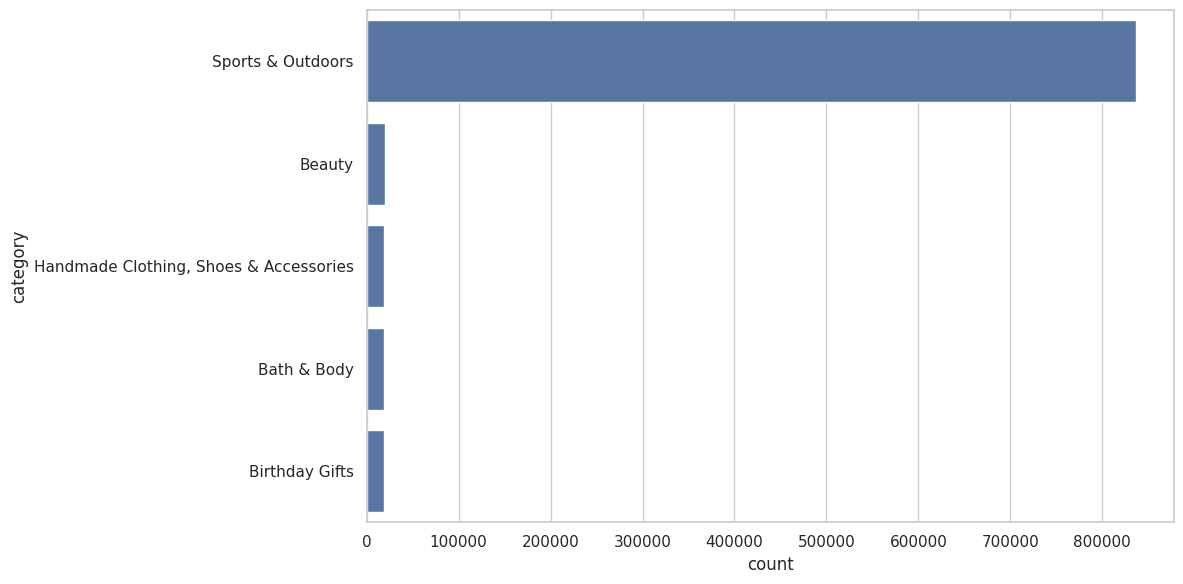

In [17]:
####
sns.barplot(
    x="count",
    y='category',
    data=df_freq_cat_top5,
    legend=True,
)
plt.tight_layout()       # Prevent label cutoff
plt.show()

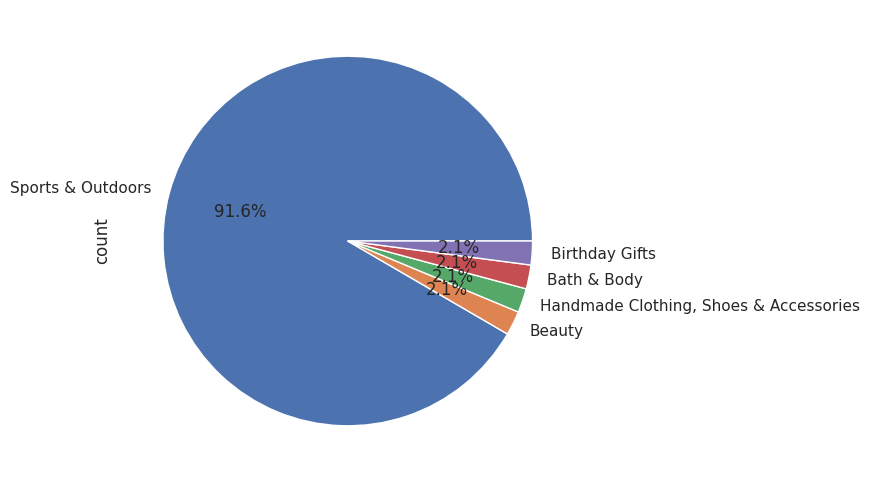

In [18]:
freq_cat_top5.plot(
    kind='pie', autopct='%1.1f%%'
)
plt.show()

**Insights**  
1. Based on the bar plot we can say that the most popular product on Amazon UK is: Sports and Outdoors.
2. It represents a proportion of 34% of the products in the dataset
3. Based on the pie plot we confirm that Sports and Outdoors is the most populat product on Amazon UK and represents ~92% of the first 5 top frequently ordered products



### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?



In [19]:
### Measure the centrality ###
avg_price = float(aws_products['price'].mean())
median_price = float(aws_products['price'].median())
mode_price = float(aws_products['price'].mode())

print('The average price of the products is {:.2f}'.format(avg_price)) 
print('The median price of the products is {:.2f}'.format(median_price)) 
print('The mode price of the products is {:.2f}'.format(mode_price)) 


The average price of the products is 89.24
The median price of the products is 19.09
The mode price of the products is 9.99


**Insights** from the centrality Statistics on 'price', we can conclude that:

1. The average price of the products in the dataset is approximately `89.24`pounds.
2. The average price (`89.24`) is much higher and represents almost 9 times the mode price (`9.99`)
3. The median price stands at `19.09`. As the median is lower than the mean, we have a skew in the distribution of prices towards higher values.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [20]:
### Measure the dispersion ###
std_price = float(aws_products['price'].std())
var_price = float(aws_products['price'].var())
range_price = float(aws_products['price'].max() - aws_products['price'].min())

Q1 = aws_products['price'].quantile(0.25)
Q3 = aws_products['price'].quantile(0.75)
IQR = float(Q3 - Q1)

print('The variance and std in the price values are respectively {:.2f} and {:.2f}'.format(var_price, std_price))
print('The range of price values is approximately {:.2f} standing between {:.2f} and {:.2f}'.format(range_price, aws_products['price'].min(),aws_products['price'].max()))
print('The interquartile range (IQR), is between {:.2f} and {:.2f} with a value of {:.2f}.'.format(Q1, Q3,  IQR))

The variance and std in the price values are respectively 119445.49 and 345.61
The range of price values is approximately 100000.00 standing between 0.00 and 100000.00
The interquartile range (IQR), is between 9.99 and 45.99 with a value of 36.00.


In [21]:
CV = round(float(num.price.std()/num.price.mean()), 2) ##>>> coefficeint of variation
print(CV)

3.87


**Insights** from Summary Statistics for 'price':

1. The range in prices is approximately `100000.0`, highlighting a wide range of values in the dataset.

2. Even with a high range of values the standard deviation is approximately `345.61`. The std is higher than the IQR this indicates that sale prices have a hight dispersion from the average. This is probably affected by some extreme values in the data that are affecting the overall statistics.

3. The interquartile range (IQR) is between `9.99` and `45.99`. This means that 50% of the products in the dataset were sold with `36` pounds.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

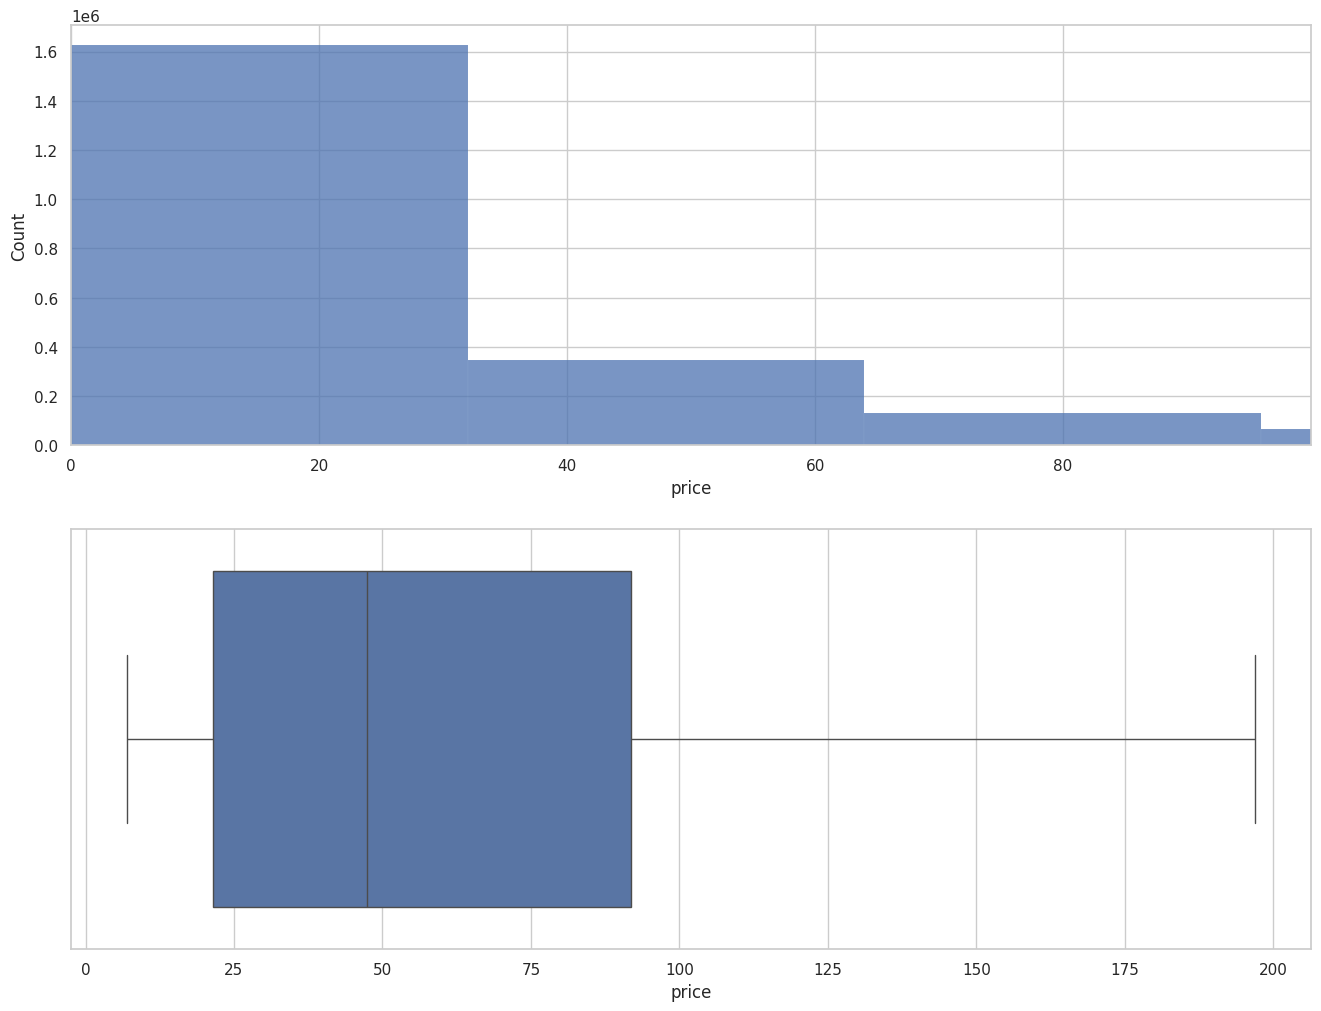

In [ ]:
### Visualizstion ###
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

sns.histplot(aws_products.price, bins= 'auto', ax=axes[0], legend=True)

### The problem with the histogram is that it very affected with the maximum value which is an extreme value considering 
# the average pattern of the price values >> Solution for visualization might be to limit limit the x_axis range to a max_value
# example >> Qu75 + 1.5*IQR
max_x = Q3 + 1.5 * IQR
min_x = Q1 - 1.5 * IQR
axes[0].set_xlim(max(aws_products['price'].min(), min_x), min(aws_products['price'].max(), max_x))  # Limit x-axis

sns.boxplot(x="price", data=aws_products, ax=axes[1], showfliers=False, legend=True)

plt.show()

In [35]:
avg_price_cat = aws_products[['price', 'category']].groupby('category').agg('mean').sort_values(by='price', ascending=False).reset_index()
avg_price_cat

,category,price
0,Laptops,1087.987827
1,3D Printers,1018.036129
2,Desktop PCs,926.816064
3,Home Office Furniture,622.135898
4,Test & Measurement,559.382973
...,...,...
291,Bedding Accessories,8.835220
292,Adapters,8.750197
293,Signs & Plaques,8.275136
294,Arts & Crafts,8.182523


In [56]:
n = 30
top_nCategories = aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = aws_products[aws_products.category.isin(top_nCategories)]

<Axes: xlabel='price', ylabel='category'>

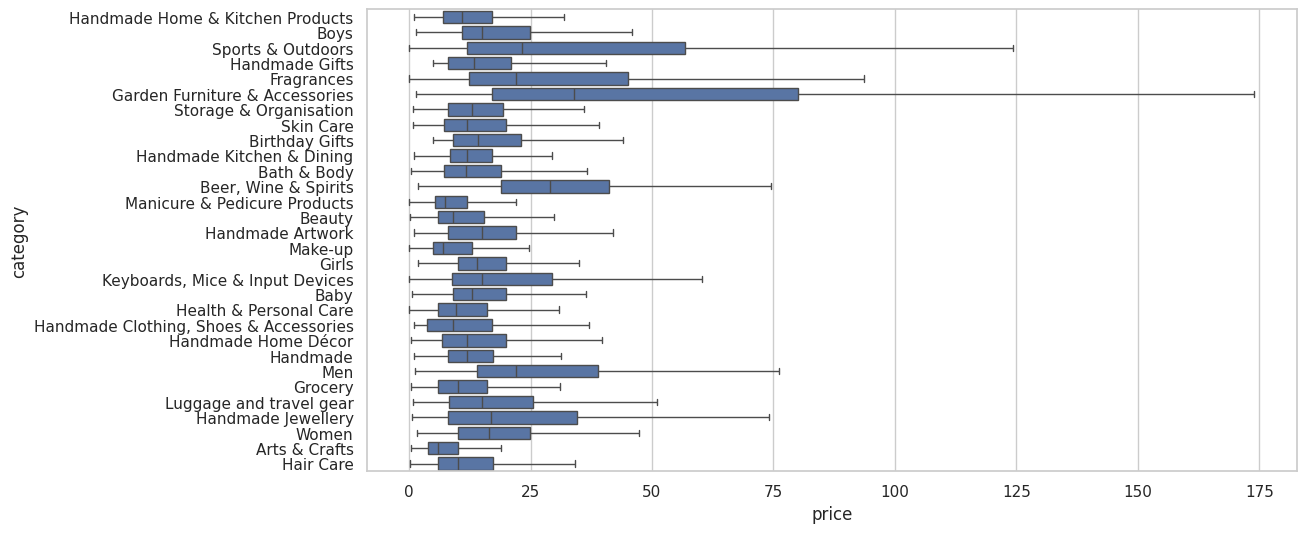

In [57]:
sns.boxplot(data=aws_products_topn, x="price", y='category', showfliers=False, legend=True)

**Insights** from visualizations of 'price', we note that:#
1. Most of the price values are under `100`(Q3 + 1.5 * IQR) and particulary under `45.99` (Q3)
2. The visulization of the distribution with a histogram was not readble. As a solution we delimited the x-axis to the most common range of prices values (0-100)
3. There are extreme values which are affecting the overall distribution:
    - On average the laptop  and other IT equipements category has the highest prices
    - Sports and Outdoors has the highest extreme values in the most frequently bought products >> higher than
    
=>> We see that it would be better to do a data binning and analyse the most frequent bought data vs. long term bought data


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [58]:
### Measure the centrality ###
avg_rating = float(aws_products['stars'].mean())
median_rating = float(aws_products['stars'].median())
mode_rating = float(aws_products['stars'].mode())

print('The average rating value of the products is {:.2f}'.format(avg_rating))
print('The median rating value of the products is {:.2f}'.format(median_rating)) 
print('The mode rating value of the products is {:.2f}'.format(mode_rating))

The average rating value of the products is 2.15
The median rating value of the products is 0.00
The mode rating value of the products is 0.00


In [61]:
aws_products_withRatings = aws_products[aws_products.stars != float(0)]


### Measure the centrality ###
avg_rating = float(aws_products_withRatings['stars'].mean())
median_rating = float(aws_products_withRatings['stars'].median())
mode_rating = float(aws_products_withRatings['stars'].mode())

print('The average rating value of the products is {:.2f}'.format(avg_rating))
print('The median rating value of the products is {:.2f}'.format(median_rating)) 
print('The mode rating value of the products is {:.2f}'.format(mode_rating))

The average rating value of the products is 4.32
The median rating value of the products is 4.40
The mode rating value of the products is 4.50


**Insights** from the centrality Statistics on 'stars', we can conclude that:

1. The average rating of the products in the dataset is approximately `2.15`.
2. The average rating value (`2.15`) is higher than the mode and median values (`0.00`)
3. The median price stands at `0.00`. As the median is lower than the mean, we have a skew in the distribution of prices towards higher values: Positive skew distribution
4. The customers tend to give a rate of `0.00`, which means that the customer did not give any rating >> These products should be removed for this analysis.
5. With the filered data we see that the average, mean and mode have close values
6. The customers tend to give high ratings


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [67]:
## Measures of Dispersion##

std_rating = float(aws_products['stars'].std())
var_rating = float(aws_products['stars'].var())

max_rating = aws_products['stars'].max()
min_rating = aws_products['stars'].min()
range_rating = float(max_rating - min_rating)

Q1_rating = aws_products['stars'].quantile(0.25)
Q3_rating = aws_products['stars'].quantile(0.75)
IQR_rating = float(Q3_rating - Q1_rating)


print('The variance and std in the ratings values are respectively {:.2f} and {:.2f}'.format(var_rating, std_rating))
print('The range of the ratings values is approximately {:.2f} standing between {:.2f} and {:.2f}'.format(range_rating, min_rating, max_rating))
print('The interquartile range (IQR), is between {:.2f} and {:.2f} with a value of {:.2f}.'.format(Q1_rating, Q3_rating, IQR_rating))

The variance and std in the ratings values are respectively 4.82 and 2.19
The range of the ratings values is approximately 5.00 standing between 0.00 and 5.00
The interquartile range (IQR), is between 0.00 and 4.40 with a value of 4.40.


In [68]:
CV_rating = std_rating / avg_rating
CV_rating

0.5081694105272834

In [69]:
## Measures of Dispersion##

std_rating = float(aws_products_withRatings['stars'].std())
var_rating = float(aws_products_withRatings['stars'].var())

max_rating = aws_products_withRatings['stars'].max()
min_rating = aws_products_withRatings['stars'].min()
range_rating = float(max_rating - min_rating)

Q1_rating = aws_products_withRatings['stars'].quantile(0.25)
Q3_rating = aws_products_withRatings['stars'].quantile(0.75)
IQR_rating = float(Q3_rating - Q1_rating)

print('After removing the zero rated values:')
print('The variance and std in the ratings values are respectively {:.2f} and {:.2f}'.format(var_rating, std_rating))
print('The range of the ratings values is approximately {:.2f} standing between {:.2f} and {:.2f}'.format(range_rating, min_rating, max_rating))
print('The interquartile range (IQR), is between {:.2f} and {:.2f} with a value of {:.2f}.'.format(Q1_rating, Q3_rating, IQR_rating))

After removing the zero rated values:
The variance and std in the ratings values are respectively 0.31 and 0.56
The range of the ratings values is approximately 4.00 standing between 1.00 and 5.00
The interquartile range (IQR), is between 4.10 and 4.60 with a value of 0.50.


In [70]:
CV_rating = std_rating / avg_rating
CV_rating

0.1285635754330601

**Insights** from Summary Statistics for 'rating':
1. The range in rating values is approximately `5.00`, highlighting a wide range of values in the dataset from 0.00 to 5.00.
2. The standard deviation is approximately `2.19` which is close to the average value. This indicates that ratings either have a high dispersion from the average or that is a two mode distribution.
3. The interquartile range (IQR) is between `0.00` and `4.40`. This means that 50% of the products in the dataset were rated with `4.40`. >> This is a high value!

AFTER CLEANING THE DATA:
1. The std and IQR have close values showing a low variation in the data >> the rating values look more consistent
2. the rating values are high on average (4.32)


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?


In [71]:
## Shape of the Distribution ##

skewness_rating = round(float(aws_products['stars'].skew()), 2)
kurtosis_rating = round(float(aws_products['stars'].kurtosis()), 2)

print('The skewness of the rating values is {:.2f}'.format(skewness_rating))
print('The kurtosis of the rating values is {:.2f}'.format(kurtosis_rating))

The skewness of the rating values is 0.08
The kurtosis of the rating values is -1.93


In [72]:
## Shape of the Distribution ##

skewness_rating = round(float(aws_products_withRatings['stars'].skew()), 2)
kurtosis_rating = round(float(aws_products_withRatings['stars'].kurtosis()), 2)

print('After removing the zero rated values:')
print('The skewness of the rating values is {:.2f}'.format(skewness_rating))
print('The kurtosis of the rating values is {:.2f}'.format(kurtosis_rating))

After removing the zero rated values:
The skewness of the rating values is -2.38
The kurtosis of the rating values is 9.78


- **Skewness = 0:**  
     The distribution is perfectly symmetrical, resembling a normal distribution.
- **Skewness > 0:**  
     The distribution is **positively skewed** (right-skewed).  
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.
- **Skewness < 0:**  
     The distribution is **negatively skewed** (left-skewed).  
     - Longer tail on the **left** side.  
     - The bulk of the data is concentrated on the **right**.

**Insights** from the centrality Statistics on 'rating', we can conclude that:

Before careful cleaning of the data we got misleading insights:
1. The rating values are not normally distributed because the avg != median and the mode.
2. The skewness in the ratings values is `0.08` slightly above zero. We conform here a slight skew in the distribution of rating values towards higher values: Positive skew distribution

After cleaning the data:
1. The average, median and mode have close values but still avg < median < mode: Negatively skew
2. The skewness in the ratings values is `-2.38`. We confirm here a skew in the distribution of rating values towards low values: Negative skew distribution



4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

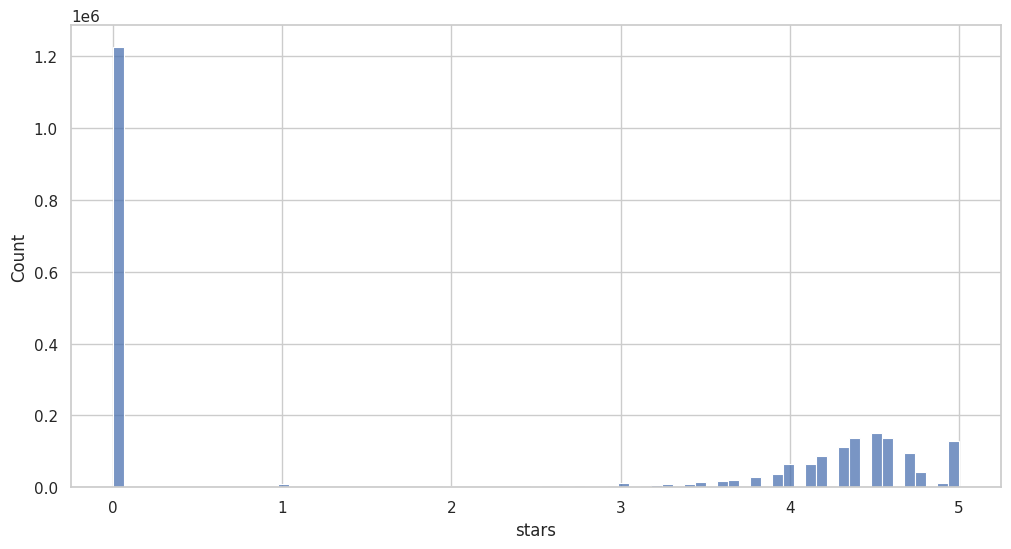

In [73]:
## Viz ##
sns.histplot(aws_products.stars, bins="auto") ##, kde=True
plt.show()


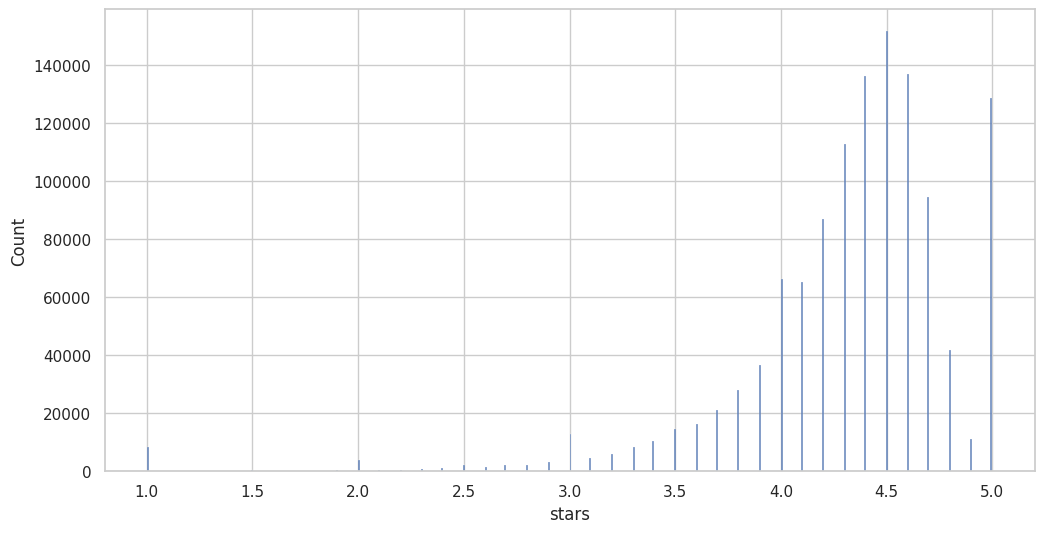

In [74]:
sns.histplot(aws_products_withRatings.stars, bins="auto") ##, kde=True
plt.show()

**Insights** 
1. The most common rating value is 4.5 >> the mode with the cleaned data
